# 06 - Evaluation, calibration and uncertainty (Week 8)

For every finished run (12 of them) this notebook measures, **on that run's own test set**:
accuracy, balanced accuracy, macro-F1, per-class sensitivity / precision, one-vs-rest AUC, confusion matrix;
temperature scaling (T fitted on the **validation** logits only) and ECE (15 bins) with reliability diagrams;
MC dropout (30 passes on the classifier head), predictive entropy, accuracy-vs-coverage and the
"refer to radiologist" rule (confidence < 0.70); model size, parameters, CPU and GPU latency.

All code is in `src/evaluate.py`. It writes `metrics.json` into each run folder, stores the temperature in
`config.json`, and `outputs/results/week8_results.csv` holds one row per run.
The test sets were not used for training, early stopping or fitting T.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, display
from src import evaluate as ev
from src.data import CLASSES, _save
PLOTS = Path('outputs/plots/week8'); RUNS = Path('outputs/runs')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else '-')
print('settings: bins', ev.N_BINS, '| MC passes', ev.MC_PASSES, '| MC dropout p', ev.MC_P, '| refer below', ev.REFER_BELOW)

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu126 | CUDA True | NVIDIA GeForce GTX 1650 Ti
settings: bins 15 | MC passes 30 | MC dropout p 0.3 | refer below 0.7


## 1. Smoke test on one run (v1_clean / mobilenetv3_small_100)

Before the full loop we evaluate one small run and check that the numbers are sane. The most important check:
the validation macro-F1 **recomputed here** must match the value logged during training (this checks that loading
`best.pt` and the preprocessing are identical to training). The match is exact for the float32-trained runs; runs trained with
float16 autocast can differ by a few thousandths because this evaluation runs in float32, hence the 0.005 tolerance.

In [2]:
run = RUNS / 'v1_clean' / 'mobilenetv3_small_100'
m = json.loads((run / 'metrics.json').read_text()) if (run / 'metrics.json').exists() else ev.evaluate_run(run)   # reuse the saved result if there is one
chk = m['checks']
print(chk)
assert abs(chk['val_macro_f1_recomputed'] - chk['val_macro_f1_training']) < 5e-3, 'val macro-F1 differs from training log'
assert chk['probs_sum_to_one'] and chk['same_predictions_after_scaling']
assert sum(map(sum, m['test']['confusion_matrix'])) == m['n_test']
assert m['calibration']['val_nll_after'] <= m['calibration']['val_nll_before'] + 1e-9
assert 0 <= m['calibration']['after']['ece'] <= 1
print('smoke test OK: accuracy %.4f, T = %.3f, ECE %.3f -> %.3f' % (m['test']['accuracy'], m['calibration']['temperature'],
      m['calibration']['before']['ece'], m['calibration']['after']['ece']))

{'val_macro_f1_recomputed': 0.9809237193004965, 'val_macro_f1_training': 0.9809237193004965, 'probs_sum_to_one': True, 'same_predictions_after_scaling': True}
smoke test OK: accuracy 0.9788, T = 0.537, ECE 0.110 -> 0.014


## 2. Evaluate all runs

One run at a time (4 GB GPU). Runs that already have an up-to-date `metrics.json` are skipped.

In [3]:
df = ev.evaluate_all()
print(df.shape)

v1_clean_efficientnet_b0                already evaluated (metrics.json is newer than best.pt)
v1_clean_mobilenetv3_small_100          already evaluated (metrics.json is newer than best.pt)
v1_clean_resnet50                       already evaluated (metrics.json is newer than best.pt)
v1_clean_vgg16                          already evaluated (metrics.json is newer than best.pt)
v1_original_efficientnet_b0                already evaluated (metrics.json is newer than best.pt)
v1_original_mobilenetv3_small_100          already evaluated (metrics.json is newer than best.pt)
v1_original_resnet50                       already evaluated (metrics.json is newer than best.pt)
v1_original_vgg16                          already evaluated (metrics.json is newer than best.pt)
v2_clean_efficientnet_b0                already evaluated (metrics.json is newer than best.pt)
v2_clean_mobilenetv3_small_100          already evaluated (metrics.json is newer than best.pt)
v2_original_efficientnet_b0           

## 3. Results table (test sets)

`original` = the dataset's own Training/Testing split (contains duplicates that leak into the test set);
`clean` = the leakage-free split. Each run is scored on **its own** test set, so the two are not the same images
and the clean test set is also much smaller (see the `n_test` column).

In [4]:
cols = ['version', 'split', 'model', 'n_test', 'accuracy', 'balanced_acc', 'macro_f1', 'macro_auc', 'epochs_run', 'stopped_by']
df[cols].round(4)

,version,split,model,n_test,accuracy,balanced_acc,macro_f1,macro_auc,epochs_run,stopped_by
0,v1,clean,efficientnet_b0,520,0.9538,0.9588,0.9541,0.9958,3,target_acc
1,v1,clean,mobilenetv3_small_100,520,0.9788,0.9816,0.9756,0.9972,20,max_epochs
2,v1,clean,resnet50,520,0.9481,0.9451,0.9404,0.9928,6,target_acc
3,v1,clean,vgg16,520,0.9269,0.9236,0.9169,0.9849,10,target_acc
4,v1,original,efficientnet_b0,1311,0.9878,0.9868,0.9872,0.9996,9,patience
5,v1,original,mobilenetv3_small_100,1311,0.9908,0.9901,0.9905,0.9997,18,patience
6,v1,original,resnet50,1311,0.8848,0.8755,0.8815,0.9810,3,target_acc
7,v1,original,vgg16,1311,0.9184,0.9131,0.9134,0.9920,5,user_stop
8,v2,clean,efficientnet_b0,538,0.9164,0.9262,0.9132,0.9866,3,target_acc
9,v2,clean,mobilenetv3_small_100,538,0.9480,0.9526,0.9440,0.9923,18,patience


In [5]:
# per-class sensitivity (recall) and precision
df[['version', 'split', 'model'] + [f'sens_{c}' for c in CLASSES] + [f'prec_{c}' for c in CLASSES]].round(3)

,version,split,model,sens_glioma,sens_meningioma,sens_notumor,sens_pituitary,prec_glioma,prec_meningioma,prec_notumor,prec_pituitary
0,v1,clean,efficientnet_b0,0.944,0.936,0.983,0.971,0.988,0.904,0.937,0.971
1,v1,clean,mobilenetv3_small_100,0.983,0.957,1.000,0.986,0.994,0.978,0.923,0.986
2,v1,clean,resnet50,0.961,0.922,0.933,0.964,0.983,0.915,0.875,0.971
3,v1,clean,vgg16,0.955,0.879,0.917,0.943,0.983,0.879,0.833,0.950
4,v1,original,efficientnet_b0,0.983,0.977,1.000,0.987,0.990,0.974,0.990,0.997
5,v1,original,mobilenetv3_small_100,0.990,0.980,1.000,0.990,0.990,0.990,0.990,0.993
6,v1,original,resnet50,0.840,0.781,0.998,0.883,0.944,0.776,0.863,0.989
7,v1,original,vgg16,0.977,0.895,0.980,0.800,0.893,0.830,0.966,0.992
8,v2,clean,efficientnet_b0,0.888,0.893,0.966,0.958,0.971,0.893,0.838,0.913
9,v2,clean,mobilenetv3_small_100,0.963,0.893,0.983,0.972,0.963,0.971,0.879,0.939


### 3.1 Original vs clean split (same model, same dataset version)
A drop from `original` to `clean` is the performance that was inflated by duplicates.

In [6]:
piv = df.pivot_table(index=['version', 'model'], columns='split', values=['accuracy', 'macro_f1'])
piv[('accuracy', 'drop')] = piv[('accuracy', 'original')] - piv[('accuracy', 'clean')]
piv[('macro_f1', 'drop')] = piv[('macro_f1', 'original')] - piv[('macro_f1', 'clean')]
piv.round(4)

accuracy          macro_f1          accuracy macro_f1
split                            clean original    clean original     drop     drop
version model                                                                      
v1      efficientnet_b0         0.9538   0.9878   0.9541   0.9872   0.0339   0.0331
        mobilenetv3_small_100   0.9788   0.9908   0.9756   0.9905   0.0120   0.0149
        resnet50                0.9481   0.8848   0.9404   0.8815  -0.0633  -0.0589
        vgg16                   0.9269   0.9184   0.9169   0.9134  -0.0085  -0.0035
v2      efficientnet_b0         0.9164   0.9406   0.9132   0.9398   0.0243   0.0266
        mobilenetv3_small_100   0.9480   0.9344   0.9440   0.9334  -0.0136  -0.0105

### 3.2 Confusion matrices (clean split)

v1_clean_mobilenetv3_small_100


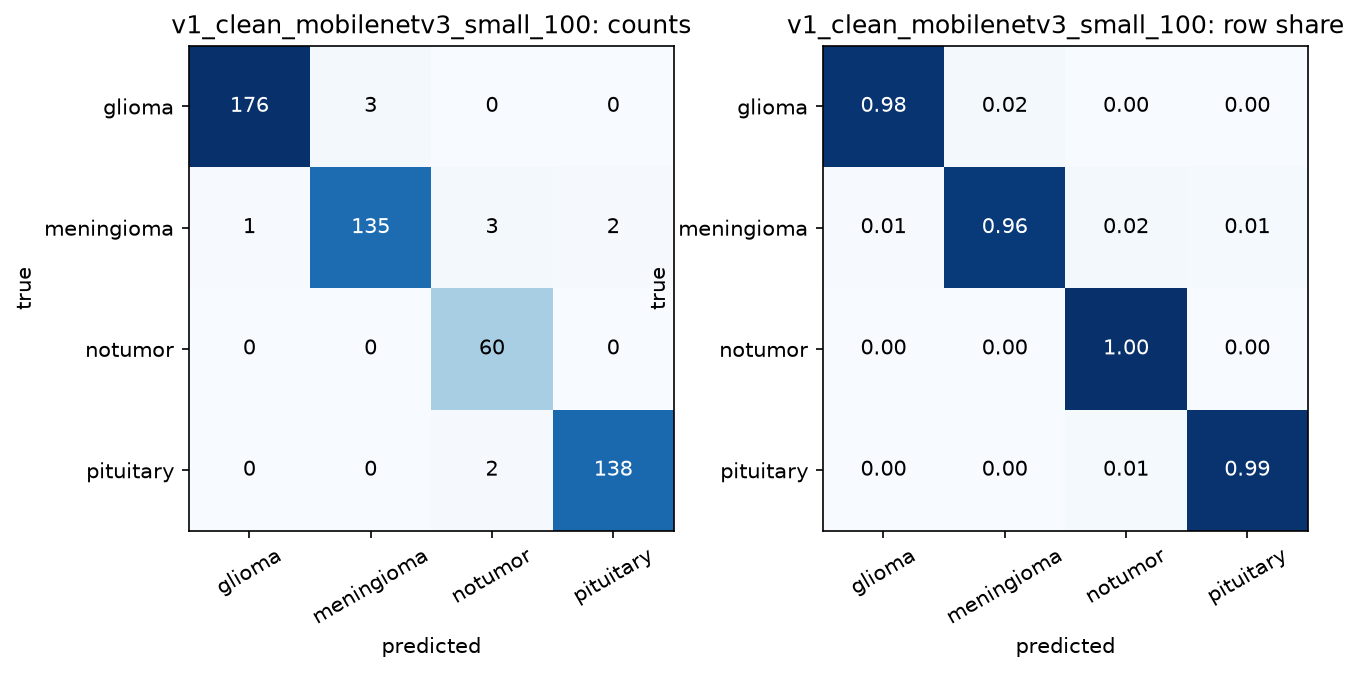

v1_clean_efficientnet_b0


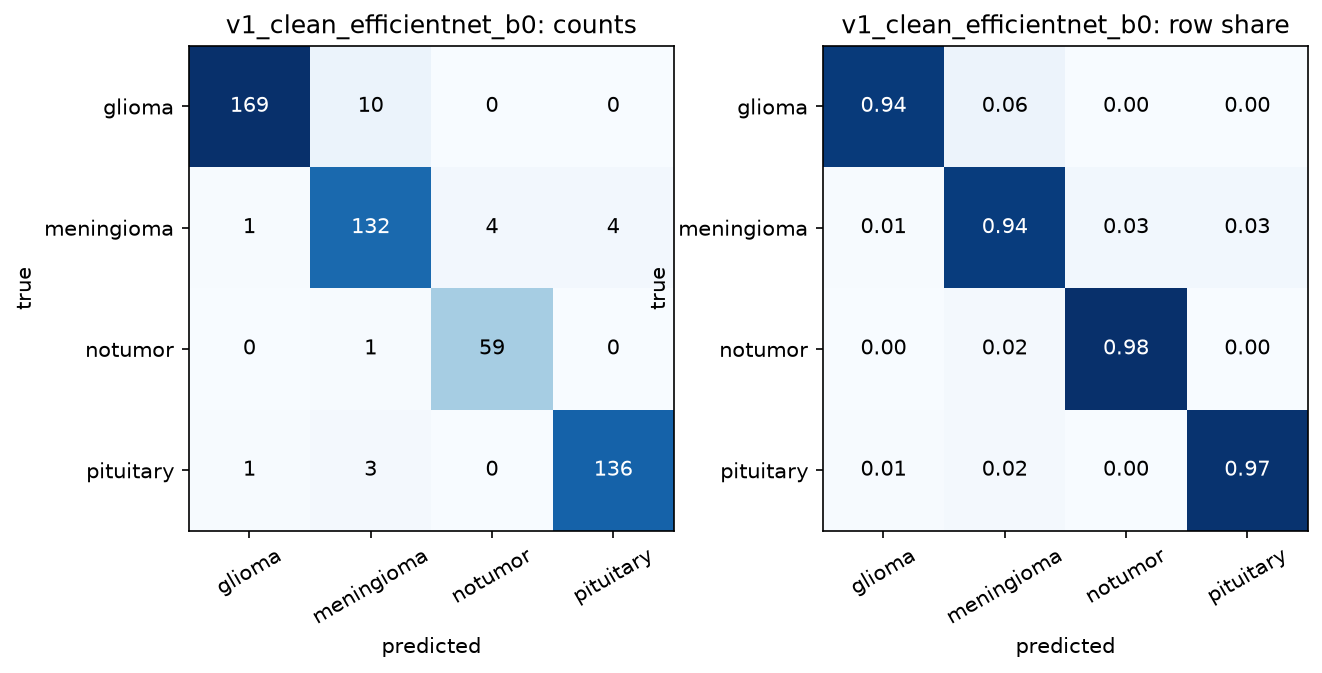

v1_clean_resnet50


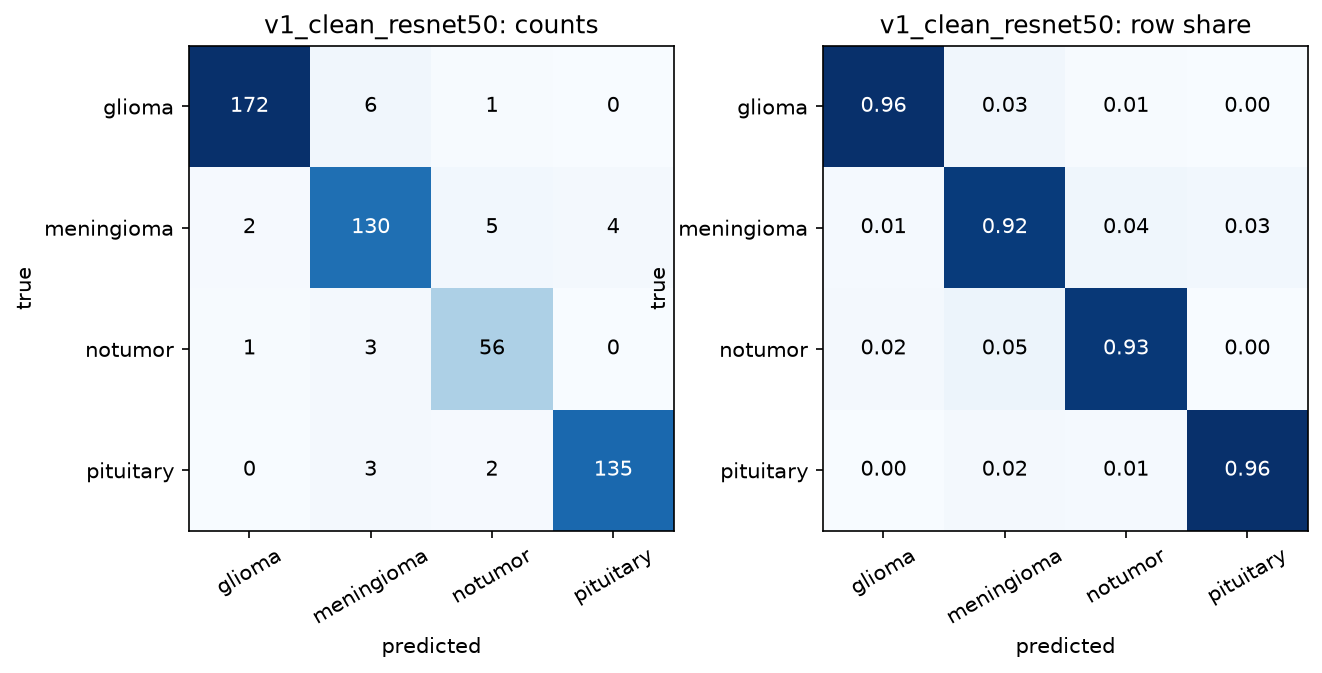

v1_clean_vgg16


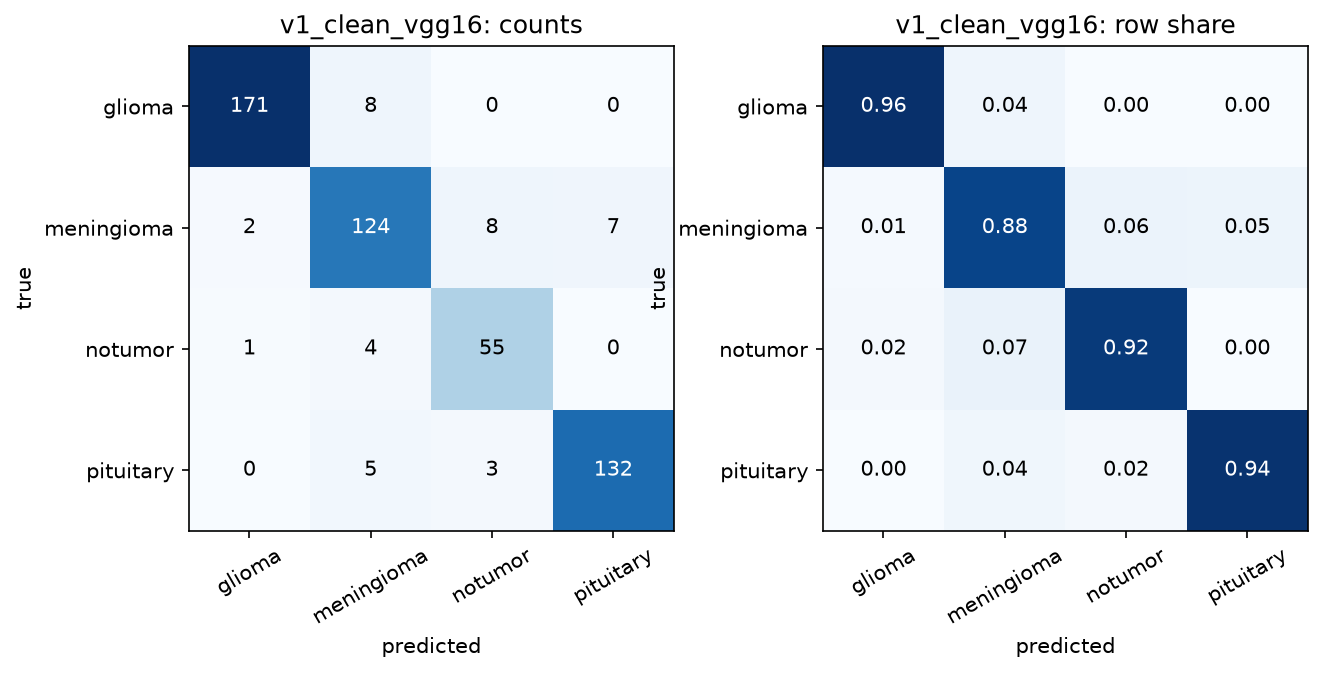

In [7]:
for name in ['v1_clean_mobilenetv3_small_100', 'v1_clean_efficientnet_b0', 'v1_clean_resnet50', 'v1_clean_vgg16']:
    print(name)
    display(ShowImage(str(PLOTS / name / 'confusion.png')))

## 4. Calibration: temperature scaling and ECE
T is fitted on the validation logits. T < 1 means the network was *under*-confident (we trained with label smoothing 0.1,
which keeps probabilities away from 1); T > 1 means over-confident. Scaling never changes the predicted class.

In [8]:
df[['version', 'split', 'model', 'temperature', 'ece_before', 'ece_after', 'nll_before', 'nll_after', 'brier_before', 'brier_after']].round(4)

,version,split,model,temperature,ece_before,ece_after,nll_before,nll_after,brier_before,brier_after
0,v1,clean,efficientnet_b0,0.6501,0.0906,0.0220,0.2177,0.1595,0.0911,0.0764
1,v1,clean,mobilenetv3_small_100,0.5371,0.1100,0.0140,0.1801,0.0966,0.0560,0.0373
2,v1,clean,resnet50,0.5920,0.0998,0.0141,0.2403,0.1706,0.0994,0.0844
3,v1,clean,vgg16,0.7332,0.0921,0.0312,0.2966,0.2579,0.1262,0.1176
4,v1,original,efficientnet_b0,0.4775,0.0782,0.0065,0.1089,0.0385,0.0272,0.0190
5,v1,original,mobilenetv3_small_100,0.4772,0.0740,0.0059,0.1017,0.0363,0.0223,0.0157
6,v1,original,resnet50,0.6086,0.0663,0.0385,0.3424,0.3120,0.1717,0.1687
7,v1,original,vgg16,0.6866,0.0898,0.0282,0.3014,0.2473,0.1373,0.1263
8,v2,clean,efficientnet_b0,0.5353,0.0909,0.0320,0.3214,0.2922,0.1418,0.1280
9,v2,clean,mobilenetv3_small_100,0.5790,0.0914,0.0276,0.2606,0.2204,0.1011,0.0922


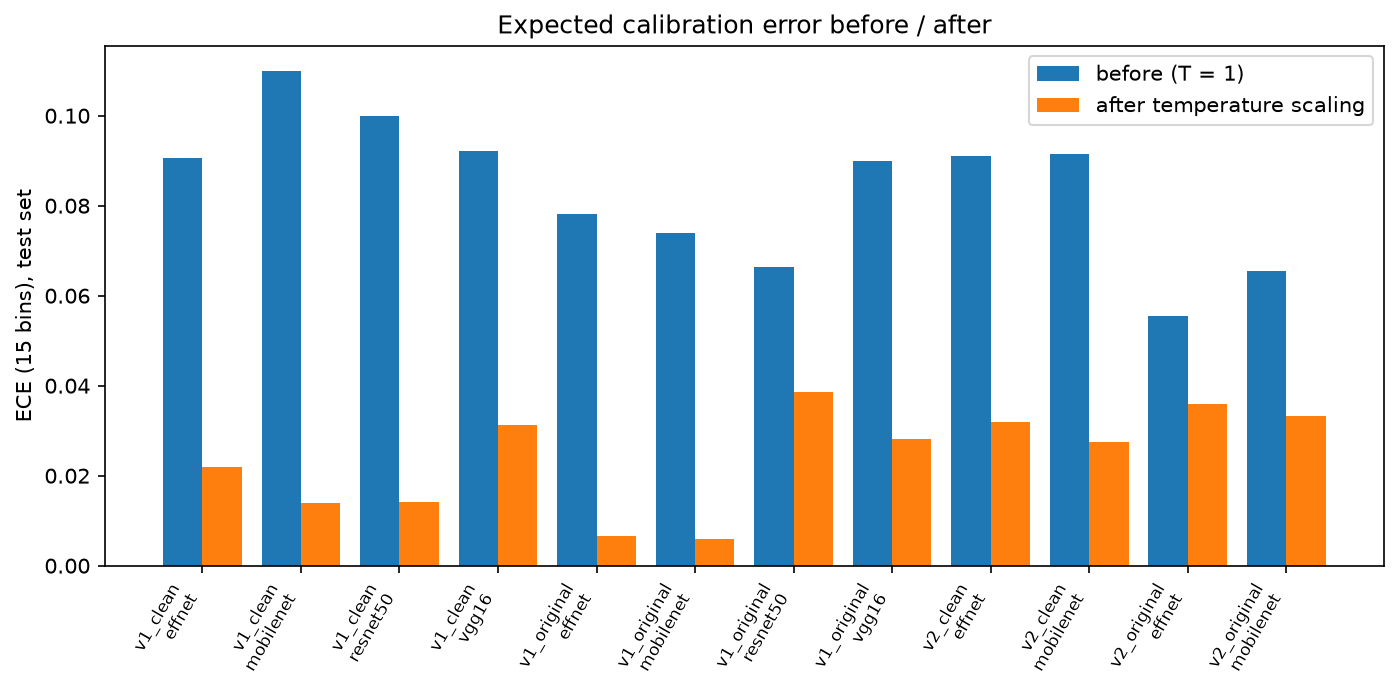

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
labels = (df['version'] + '_' + df['split'] + '\n' + df['model'].str.replace('mobilenetv3_small_100', 'mobilenet').str.replace('efficientnet_b0', 'effnet'))
x = np.arange(len(df))
ax.bar(x - 0.2, df['ece_before'], 0.4, label='before (T = 1)')
ax.bar(x + 0.2, df['ece_after'], 0.4, label='after temperature scaling')
ax.set_xticks(x, labels, rotation=60, ha='right', fontsize=8)
ax.set_ylabel('ECE (15 bins), test set'); ax.legend(); ax.set_title('Expected calibration error before / after')
display(ShowImage(str(_save(fig, PLOTS, 'ece_before_after.png'))))

Reliability diagrams (bar height = accuracy in the confidence bin, dashed line = perfect calibration):

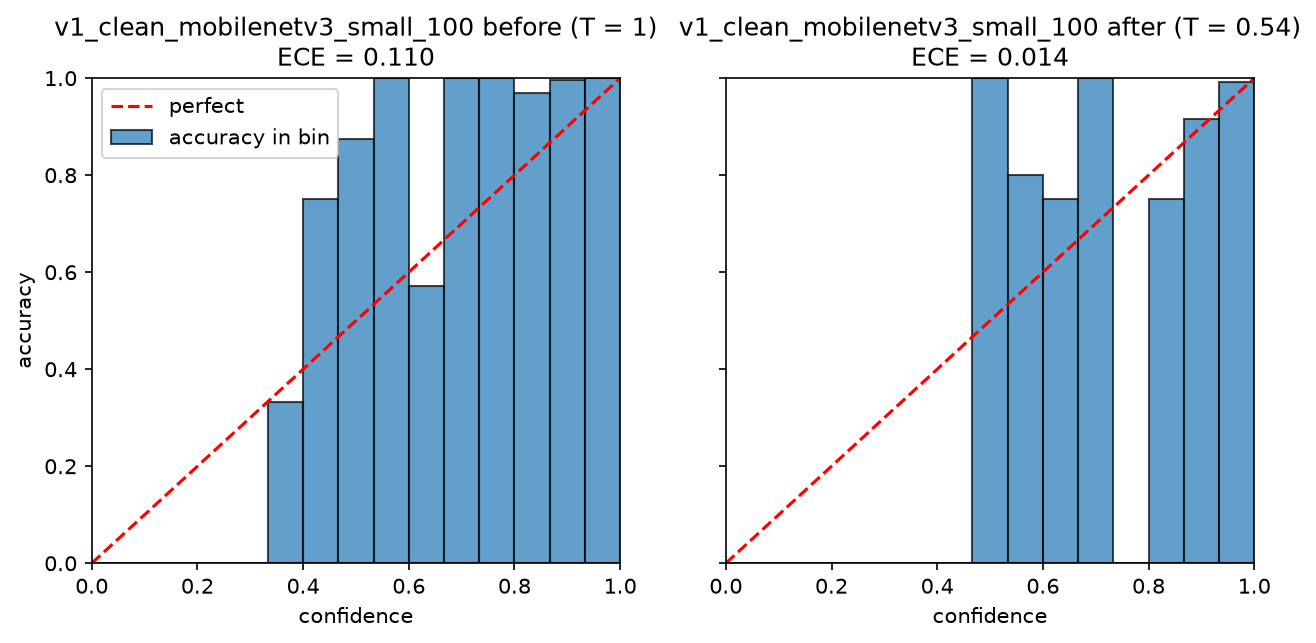

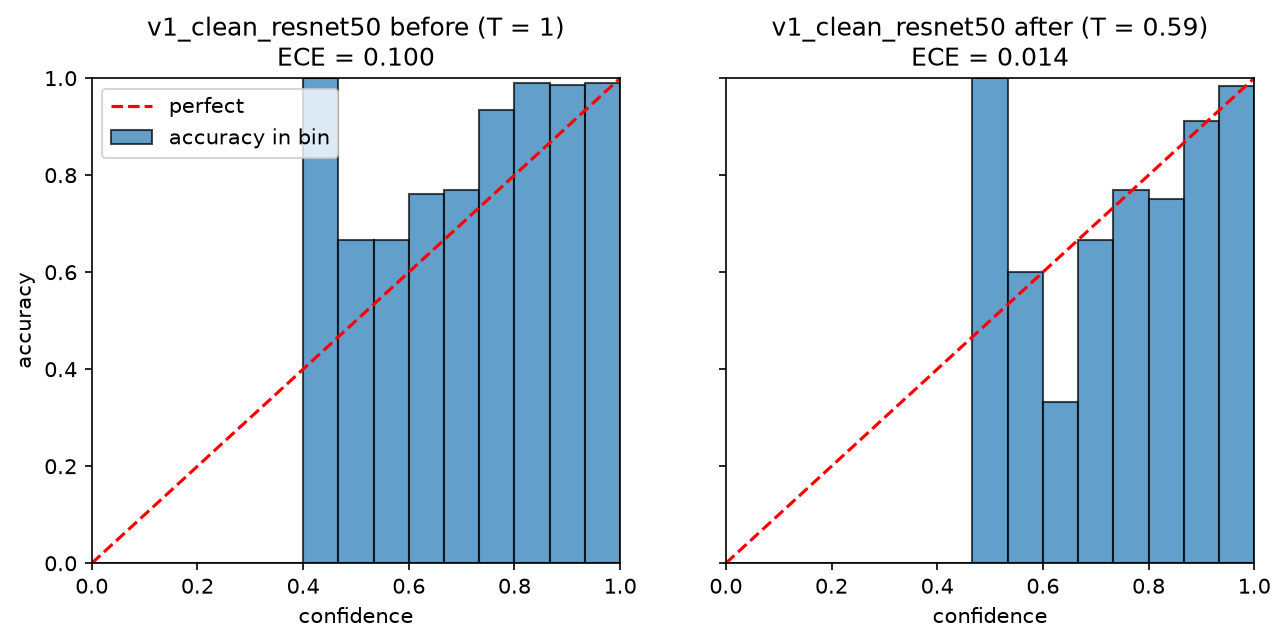

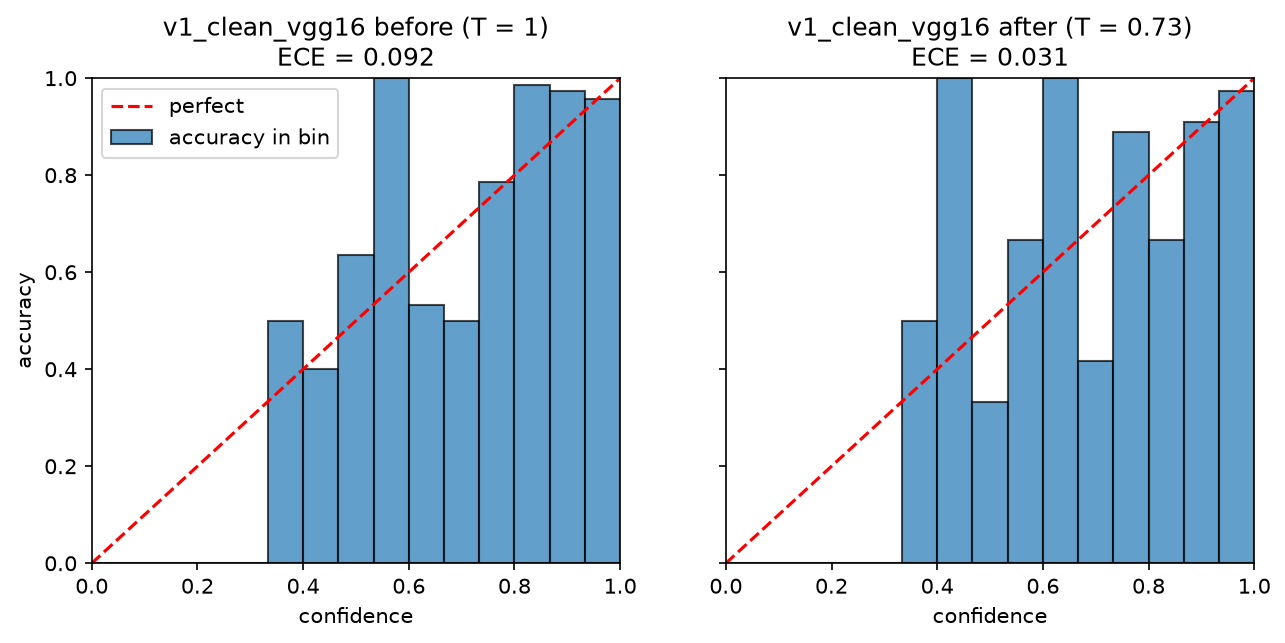

In [10]:
for name in ['v1_clean_mobilenetv3_small_100', 'v1_clean_resnet50', 'v1_clean_vgg16']:
    display(ShowImage(str(PLOTS / name / 'reliability.png')))

## 5. MC dropout, uncertainty and "refer to radiologist"
The networks were trained **without** dropout, so MC dropout here is *post-hoc*: dropout (p = 0.3) is switched on for the
feature vector that enters the last Linear layer and 30 passes are averaged (each pass uses the fitted temperature).
`p` was fixed before looking at any result and not tuned.

Referral rule (main): temperature-scaled confidence < 0.70. The `_mc` columns use the MC-averaged probability instead.

In [11]:
df[['version', 'split', 'model', 'accuracy', 'mc_acc', 'mc_mean_entropy', 'entropy_correct', 'entropy_wrong',
    'refer_rate', 'acc_non_referred', 'refer_rate_mc', 'acc_non_referred_mc']].round(4)

,version,split,model,accuracy,mc_acc,mc_mean_entropy,entropy_correct,entropy_wrong,refer_rate,acc_non_referred,refer_rate_mc,acc_non_referred_mc
0,v1,clean,efficientnet_b0,0.9538,0.9615,0.4634,0.4509,0.7749,0.0404,0.9679,0.1250,0.9758
1,v1,clean,mobilenetv3_small_100,0.9788,0.9788,0.7732,0.7688,0.9785,0.0288,0.9861,0.3692,0.9939
2,v1,clean,resnet50,0.9481,0.9481,0.1843,0.1644,0.5472,0.0423,0.9639,0.0423,0.9639
3,v1,clean,vgg16,0.9269,0.9269,0.2893,0.2668,0.5743,0.0500,0.9413,0.0519,0.9432
4,v1,original,efficientnet_b0,0.9878,0.9863,0.2292,0.2209,0.8205,0.0076,0.9900,0.0221,0.9969
5,v1,original,mobilenetv3_small_100,0.9908,0.9916,0.6817,0.6790,1.0061,0.0031,0.9916,0.0755,0.9975
6,v1,original,resnet50,0.8848,0.8841,0.2545,0.2039,0.6405,0.1198,0.9289,0.1190,0.9255
7,v1,original,vgg16,0.9184,0.9199,0.3031,0.2685,0.7004,0.0824,0.9501,0.0885,0.9523
8,v2,clean,efficientnet_b0,0.9164,0.9126,0.4399,0.4034,0.8206,0.0669,0.9442,0.1394,0.9611
9,v2,clean,mobilenetv3_small_100,0.9480,0.9461,0.8133,0.8048,0.9634,0.0260,0.9542,0.4424,0.9733


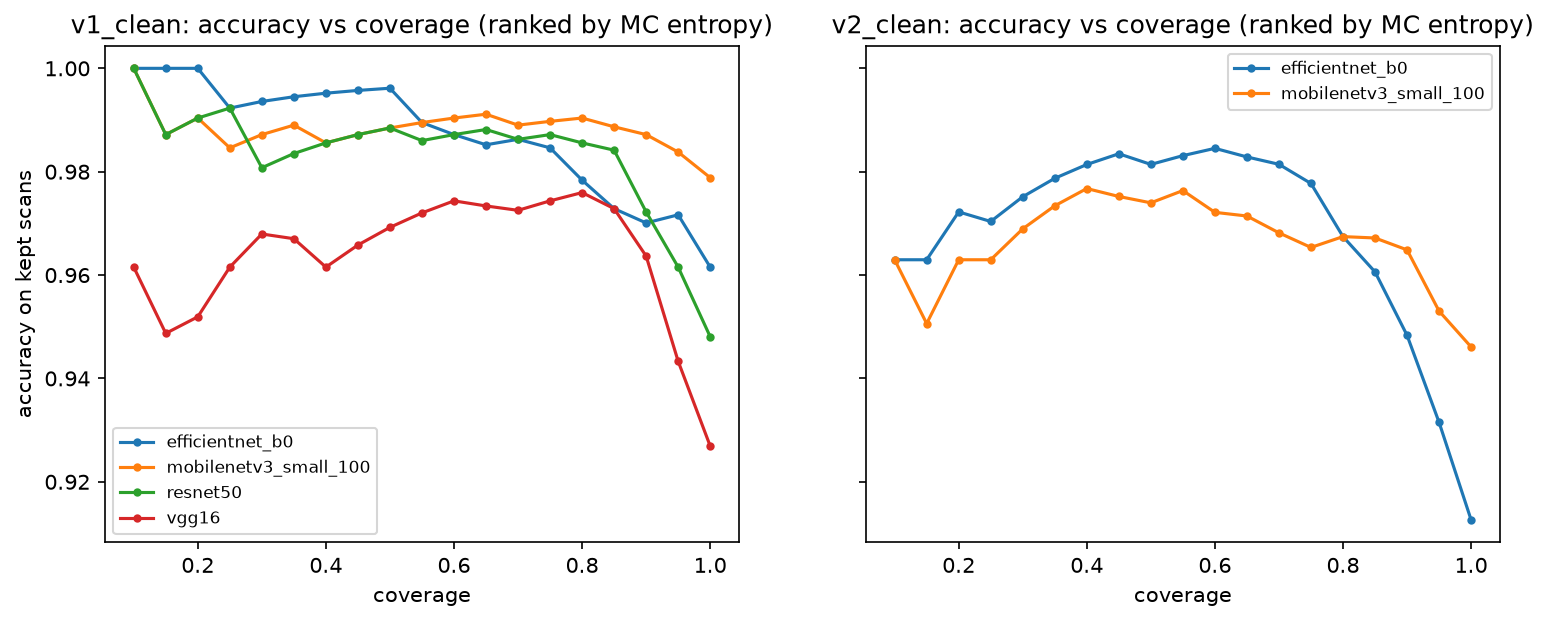

In [12]:
# accuracy-vs-coverage for all clean-split runs, read from metrics.json
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, version in zip(axes, ['v1', 'v2']):
    for run_dir in ev.finished_runs():
        if run_dir.parent.name != f'{version}_clean':
            continue
        mj = json.loads((run_dir / 'metrics.json').read_text())
        cv = mj['mc_dropout']['coverage_curve']
        ax.plot(cv['coverage'], cv['accuracy'], 'o-', ms=3, label=mj['model'])
    ax.set_title(f'{version}_clean: accuracy vs coverage (ranked by MC entropy)')
    ax.set_xlabel('coverage'); ax.legend(fontsize=8)
axes[0].set_ylabel('accuracy on kept scans')
display(ShowImage(str(_save(fig, PLOTS, 'coverage_clean.png'))))

## 6. Efficiency
Size = `best.pt` in MiB (float32 weights). Latency = forward pass for one image (batch 1), mean of 100 test images after 20 warm-up
images, float32; the input is already on the device. CPU = this laptop's CPU, default PyTorch thread count.

In [13]:
eff = df[['version', 'split', 'model', 'params_M', 'size_mb', 'cpu_ms', 'gpu_ms', 'accuracy', 'macro_f1']].round(3)
eff

,version,split,model,params_M,size_mb,cpu_ms,gpu_ms,accuracy,macro_f1
0,v1,clean,efficientnet_b0,4.013,15.588,24.230,12.514,0.954,0.954
1,v1,clean,mobilenetv3_small_100,1.522,5.932,8.144,8.908,0.979,0.976
2,v1,clean,resnet50,23.516,90.013,58.785,9.199,0.948,0.940
3,v1,clean,vgg16,134.277,512.237,282.997,20.740,0.927,0.917
4,v1,original,efficientnet_b0,4.013,15.588,23.723,12.770,0.988,0.987
5,v1,original,mobilenetv3_small_100,1.522,5.932,10.336,8.718,0.991,0.990
6,v1,original,resnet50,23.516,90.013,59.655,8.930,0.885,0.882
7,v1,original,vgg16,134.277,512.237,239.295,19.862,0.918,0.913
8,v2,clean,efficientnet_b0,4.013,15.588,22.969,13.505,0.916,0.913
9,v2,clean,mobilenetv3_small_100,1.522,5.932,8.914,9.062,0.948,0.944


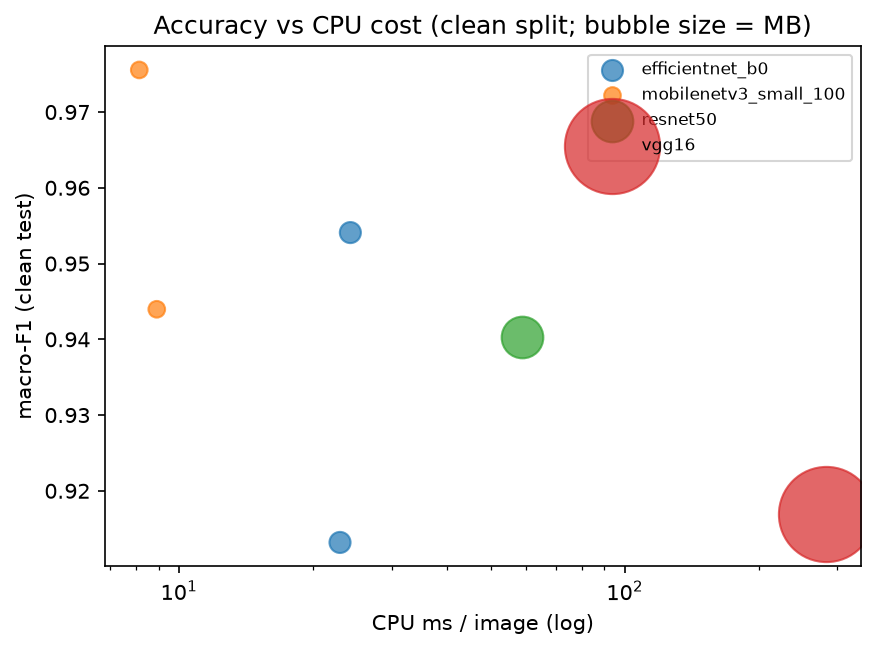

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for model, g in df[df['split'] == 'clean'].groupby('model'):
    ax.scatter(g['cpu_ms'], g['macro_f1'], s=40 + 4 * g['size_mb'], alpha=0.7, label=model)
ax.set_xscale('log'); ax.set_xlabel('CPU ms / image (log)'); ax.set_ylabel('macro-F1 (clean test)')
ax.set_title('Accuracy vs CPU cost (clean split; bubble size = MB)'); ax.legend(fontsize=8)
display(ShowImage(str(_save(fig, PLOTS, 'f1_vs_cpu.png'))))

## 7. Final checks

In [15]:
mj = {r.parent.name + '_' + r.name: json.loads((r / 'metrics.json').read_text()) for r in ev.finished_runs()}
bad = []
for name, x in mj.items():
    c = x['checks']
    if abs(c['val_macro_f1_recomputed'] - c['val_macro_f1_training']) > 5e-3: bad.append((name, 'val F1 differs'))
    if not (c['probs_sum_to_one'] and c['same_predictions_after_scaling']): bad.append((name, 'prob check'))
    if sum(map(sum, x['test']['confusion_matrix'])) != x['n_test']: bad.append((name, 'confusion matrix size'))
print('runs:', len(mj), '| NaN cells in results table:', int(df.drop(columns=['stopped_by']).isna().sum().sum()), '| problems:', bad or 'none')
print('temperature stored in config.json:', all('temperature' in json.loads((r / 'config.json').read_text()) for r in ev.finished_runs()))

runs: 12 | NaN cells in results table: 0 | problems: none
temperature stored in config.json: True


## What we found

Every statement below is read from the tables above (single seed 42, one run per cell). The test sets are small
(520-538 images for the clean split, so one image is about 0.19 percentage points), so differences of about 1 point or less should not be over-read.

**Original vs clean split is confounded by early stopping.** Several runs stopped early at validation accuracy >= 0.92 (`target_acc`) or by hand
(`epochs_run`, `stopped_by` columns): v1 resnet50 original (3 epochs), v1 vgg16 original (5 epochs, stopped by hand), v2 mobilenet original (4 epochs),
v2 efficientnet original (2 epochs). That is why v1 resnet50 and vgg16 score *lower* on the original split than on the clean split. These pairs
say nothing about leakage. The only pair where both runs ran to patience or the epoch limit is v1 mobilenetv3_small_100: macro-F1 0.9905 (original)
vs 0.9756 (clean), a drop of 1.5 points. v1 efficientnet_b0 also drops (0.9872 to 0.9541), but its clean run stopped at epoch 3 by `target_acc`. A fair leakage
comparison needs equal training budgets (a follow-up).

**Light models match or beat the heavy baselines on the clean split, at a fraction of the cost.** On v1 clean, test macro-F1 is 0.9756 (mobilenetv3_small_100),
0.9541 (efficientnet_b0), 0.9404 (resnet50), 0.9169 (vgg16). The heavy runs there also stopped early (`target_acc`), so they may be under-trained.
Cost: mobilenet 1.52 M parameters, 5.9 MB, 8-12 ms per image on this CPU; efficientnet_b0 4.0 M, 15.6 MB, 22-24 ms; resnet50 23.5 M, 90 MB, about 59 ms;
vgg16 134 M, 512 MB, 239-283 ms. On the GPU at batch size 1 the differences are small (about 9-13 ms for the light models, about 9 ms for resnet50, about 20 ms for vgg16),
so the GPU does not show the CPU gap.

**Calibration.** All 12 runs have T < 1 (0.45 to 0.73): the networks are *under*-confident, as expected after label smoothing 0.1. Temperature scaling reduced ECE on
all 12 runs, from 0.055-0.110 to 0.006-0.039. The leakage-free validation sets (clean) give T between 0.54 and 0.73; for the original split the validation images come from the
Training folder and may have near-duplicates in the training set, so those T values are less trustworthy.

**Referral at confidence < 0.70** (temperature-scaled): 0.3% to 12.0% of scans are referred, and accuracy on the scans that are *not* referred is higher than the
overall accuracy in all 12 runs (for example v1 clean mobilenet 0.9788 to 0.9861 with 2.9% referred; v1 original resnet50 0.8848 to 0.9289 with 12.0% referred).

**MC dropout (post-hoc, p = 0.3).** MC accuracy stays within 0.8 points of the deterministic accuracy for every run. Mean predictive entropy is higher on wrongly classified scans
than on correct ones in all 12 runs, so entropy does carry information about errors. The accuracy-vs-coverage curves rise as coverage falls for most runs but are not monotone (v1 vgg16 stays at about 0.95-0.97 from 10% to 80% coverage, and the v2 clean curves peak at 40-60% coverage), so MC entropy is an imperfect ranking. The light models are far more sensitive to head dropout than the heavy ones
(entropy on correct scans 0.65-0.81 for mobilenet vs 0.16-0.27 for resnet50 and vgg16), so the MC-probability referral rate is large for mobilenet (up to 44%).
The main referral rule therefore uses the deterministic temperature-scaled confidence. Because these networks were never trained with dropout, p is arbitrary here; training with dropout is the cleaner option.

**Limitations.** Single seed; small test sets; fixed early-stopping targets differ between runs; float16-trained models were evaluated in float32 (validation macro-F1 differs from the training log by at most 0.003).